# 08 Player insights

**Objective.** Diagnostic extras, how pressure shows in execution, shot choice and hard entries. Display only.

**Inputs.** player_insights/output tables.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from common import style
from common.io import read_parquet, read_table
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

## Step 1. Data quality of tagged fields by competition type

In [2]:
from player_insights import plots as p5
display(read_table("player_insights", "e1_style_coverage.csv").round(3))
read_table("player_insights", "e2_tag_coverage.csv").round(3)

,comp_type,yorker,full_toss,slower,bouncer,wide,missing_style
0,Emerging,0.040,0.047,0.152,0.035,0.046,0.002
1,IPL,0.049,0.070,0.195,0.048,0.050,0.000
2,T20I_associate,0.031,0.036,0.137,0.042,0.047,0.001
3,T20I_full,0.041,0.054,0.180,0.043,0.047,0.004


,comp_type,aggressive,defensive,orthodox,untagged
0,Emerging,0.105,0.154,0.734,0.007
1,IPL,0.079,0.142,0.764,0.014
2,T20I_associate,0.078,0.155,0.757,0.010
3,T20I_full,0.085,0.146,0.755,0.014


## Step 2. League execution at the death

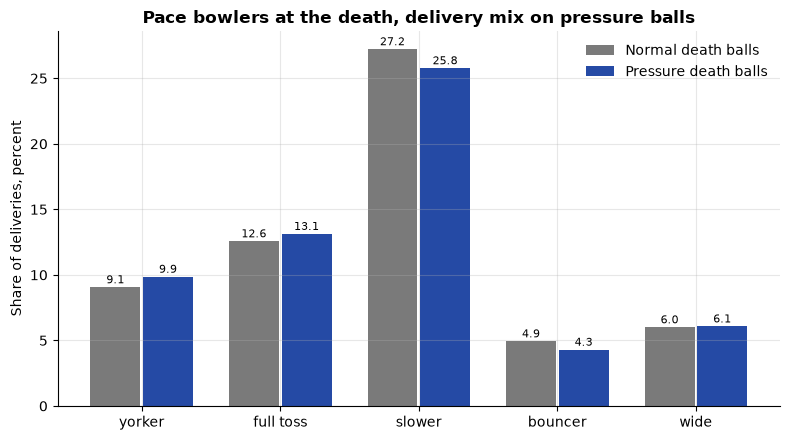

,delivery,normal,pressure,runs_normal,runs_pressure
0,yorker,0.091,0.099,0.902,0.897
1,full_toss,0.126,0.131,1.969,1.996
2,slower,0.272,0.258,1.569,1.641
3,bouncer,0.049,0.043,1.365,1.253
4,wide,0.060,0.061,NaN,NaN


In [3]:
p5.execution(); plt.show()
read_table("player_insights", "e1_league_execution.csv").round(3)

## Step 3. Pace execution, eligible bowlers

In [4]:
e1 = read_table("player_insights", "e1_pace_execution.csv")
e1[e1.eligible & (e1.press_balls >= 60)].sort_values("execution_score", ascending=False).head(10)[
    ["player_name", "press_balls", "yorker_P", "fulltoss_P", "yorker_N", "fulltoss_N", "execution_score"]].round(3)

,player_name,press_balls,yorker_P,fulltoss_P,yorker_N,fulltoss_N,execution_score
135,Xavier Bartlett,125.0,0.032,0.040,0.082,0.245,0.126
193,Yash Dayal,171.0,0.099,0.099,0.095,0.186,0.077
16,Josh Hazlewood,362.0,0.077,0.058,0.074,0.133,0.073
53,Shardul Thakur,185.0,0.092,0.146,0.089,0.214,0.061
132,Barry McCarthy,170.0,0.041,0.035,0.058,0.124,0.061
58,Jasprit Bumrah,360.0,0.111,0.139,0.162,0.254,0.060
209,Tanzim Sakib,144.0,0.062,0.069,0.065,0.138,0.055
18,Jaydev Unadkat,134.0,0.037,0.060,0.061,0.148,0.053
269,Jacob Duffy,152.0,0.046,0.053,0.034,0.103,0.052
113,Khaleel Ahmed,207.0,0.043,0.058,0.041,0.111,0.048


## Step 4. Bounce-back

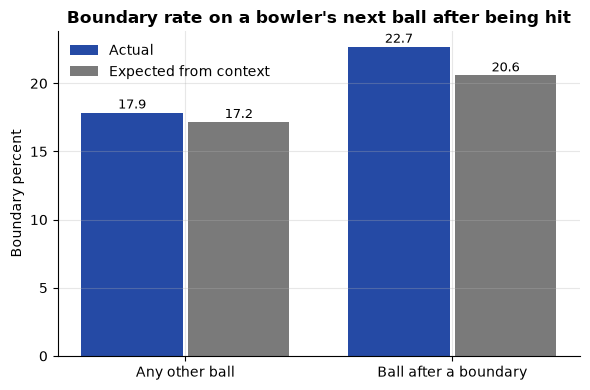

,player_id,n,sr,sb,bounce_runs,bounce_boundary,player_name,eligible
99,2933,233,-122.716,-25.627,0.467,0.097,Jasprit Bumrah,True
369,7699,75,-29.381,-5.039,0.280,0.048,Abbas Afridi,True
386,7920,137,-44.236,-8.441,0.265,0.051,Nathan Ellis,True
350,7327,109,-30.109,-5.266,0.217,0.038,Rasikh Salam,True
87,2681,171,-40.287,-5.026,0.200,0.025,Taskin Ahmed,True
323,6806,222,-50.316,-5.940,0.200,0.024,Tushar Deshpande,True
180,4373,238,-53.197,-9.569,0.198,0.036,Mustafizur Rahman,True
302,6523,128,-30.208,-5.870,0.191,0.037,Blessing Muzarabani,True
114,3275,236,-47.705,-6.566,0.179,0.025,Alzarri Joseph,True
72,2411,174,-35.697,-10.901,0.175,0.053,Sandeep Sharma,True


In [5]:
p5.bounce_back(); plt.show()
bb = read_table("player_insights", "e1_bounce_back.csv")
bb[bb.eligible].sort_values("bounce_runs", ascending=False).head(10).round(3)

## Step 5. Shot-mix drift quadrants

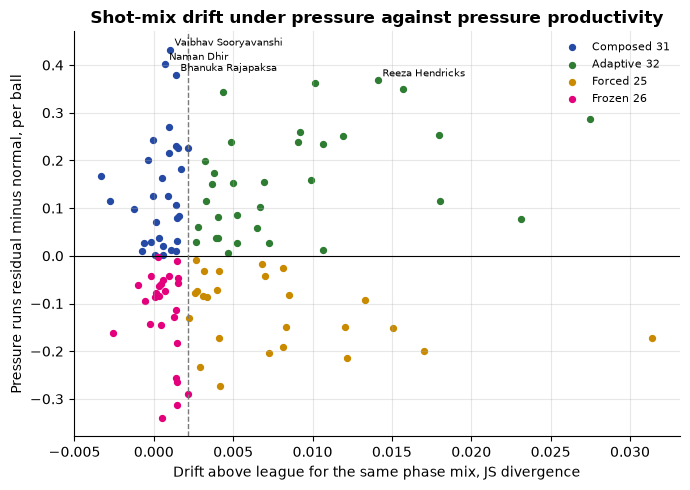

quadrant
Adaptive    32
Composed    31
Frozen      26
Forced      25
Name: count, dtype: int64

In [6]:
p5.shot_mix(); plt.show()
e2 = read_table("player_insights", "e2_shot_mix.csv")
e2[e2.eligible].quadrant.value_counts()

## Step 6. Hard entry

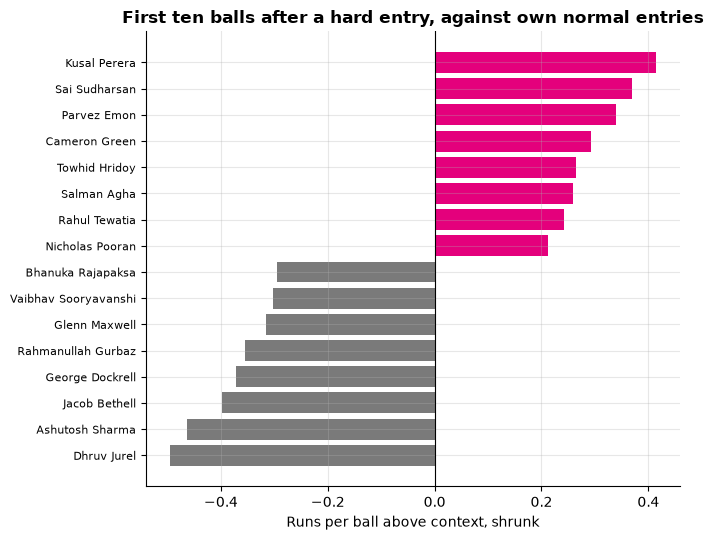

,is_hard_entry,balls,runs_pb,x_runs_pb,out_rate,x_out_rate
0,False,29001,1.2170,1.2241,0.0569,0.0568
1,True,68082,1.2417,1.2467,0.0495,0.0494


In [7]:
p5.hard_entry(); plt.show()
read_table("player_insights", "e3_league_entry.csv").round(4)

## Key findings

In [8]:
st = read_table("player_insights", "e1_style_coverage.csv").set_index("comp_type")
e2 = read_table("player_insights", "e2_shot_mix.csv")
q = e2[e2.eligible].quadrant.value_counts()
display(Markdown(f'''
- Full toss tagging runs at {st.loc["IPL", "full_toss"]:.1%} of pace balls in the IPL against {st.loc["T20I_full", "full_toss"]:.1%} in full T20Is, so execution is compared within a player's own balls, not across providers.
- Eligible batters split into {", ".join(f"{k} {v}" for k, v in q.items())}.
- Hard entries cover most innings under the literal definition, so this view stays a diagnostic.
'''))


- Full toss tagging runs at 7.0% of pace balls in the IPL against 5.4% in full T20Is, so execution is compared within a player's own balls, not across providers.
- Eligible batters split into Adaptive 32, Composed 31, Frozen 26, Forced 25.
- Hard entries cover most innings under the literal definition, so this view stays a diagnostic.


## Outputs written

player_insights/output/tables e1_*, e2_*, e3_*. Figures 08_*.png.